In [1]:
!pip install kagglehub torch torchvision scikit-learn matplotlib pillow

100%|██████████| 350M/350M [00:01<00:00, 225MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/sachinkumar413/diabetic-retinopathy-dataset/versions/1

Dataset contents:
1/
  Mild DR/
    Mild_DR_16.png
    Mild_DR_145.png
    Mild_DR_314.png
  Healthy/
    Healthy_419.png
    Healthy_738.png
    Healthy_925.png
  Severe DR/
    Severe DR_172.png
    Severe DR_33.png
    Severe DR_127.png
  Moderate DR/
    Moderate_DR.png
    Moderate_DR_735.png
    Moderate_DR_320.png
  Proliferate DR/
    Proliferate DR_68.png
    Proliferate DR_236.png
    Proliferate DR_214.png

Using dataset folder: /root/.cache/kagglehub/datasets/sachinkumar413/diabetic-retinopathy-dataset/versions/1

Classes (index -> name):
0 -> Healthy (1000 images)
1 -> Mild DR (370 images)
2 -> Moderate DR (900 images)
3 -> Proliferate DR (290 images)
4 -> Severe DR (190 images)
Total images: 2750

Training images: 1925
Validation images: 411
Test images: 414

Using device: cpu
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/h

100%|██████████| 44.7M/44.7M [00:00<00:00, 233MB/s]


=== TRAINING ===


Epoch 1/8 | Loss: 1.2333 | Train Acc: 53.35% | Val Acc: 68.37%  <- best model saved
Epoch 2/8 | Loss: 0.9770 | Train Acc: 65.45% | Val Acc: 55.47%
Epoch 3/8 | Loss: 0.9269 | Train Acc: 64.99% | Val Acc: 58.15%
Epoch 4/8 | Loss: 0.8621 | Train Acc: 67.84% | Val Acc: 66.42%
Epoch 5/8 | Loss: 0.7800 | Train Acc: 72.05% | Val Acc: 70.07%  <- best model saved
Epoch 6/8 | Loss: 0.7657 | Train Acc: 72.94% | Val Acc: 67.40%
Epoch 7/8 | Loss: 0.7458 | Train Acc: 72.88% | Val Acc: 72.02%  <- best model saved
Epoch 8/8 | Loss: 0.7381 | Train Acc: 73.92% | Val Acc: 70.07%


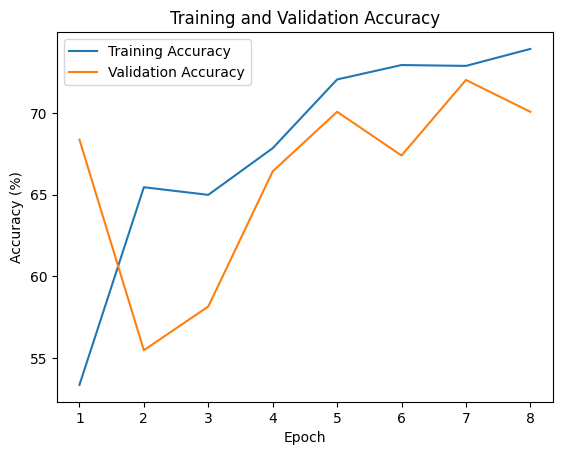


====== TEST RESULTS ======
Total Test Images: 414
Correct Predictions: 306
Test Accuracy: 73.91%
Quadratic Weighted Kappa: 0.7918

Per-class report:
                precision    recall  f1-score   support

       Healthy       0.91      0.99      0.95       150
       Mild DR       0.59      0.64      0.62        56
   Moderate DR       0.79      0.60      0.68       135
Proliferate DR       0.50      0.50      0.50        44
     Severe DR       0.41      0.62      0.49        29

      accuracy                           0.74       414
     macro avg       0.64      0.67      0.65       414
  weighted avg       0.75      0.74      0.74       414

Confusion matrix (rows = true, cols = predicted):
[[149   1   0   0   0]
 [  4  36   7   6   3]
 [  8  16  81  14  16]
 [  1   5   9  22   7]
 [  1   3   5   2  18]]


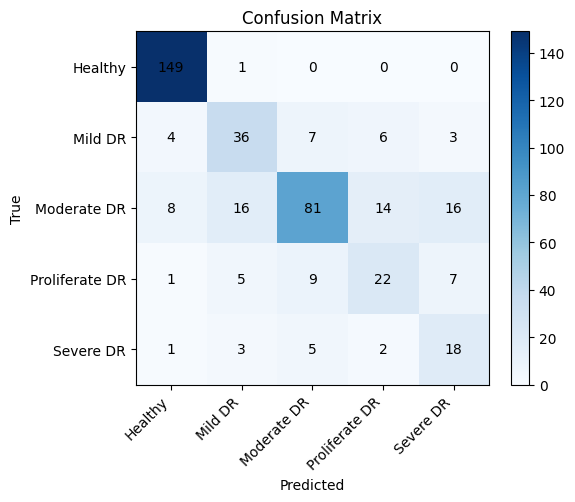


========== NEW IMAGE PREDICTION ==========
Image: Healthy_127.png
Predicted Stage: Healthy
Confidence: 99.59%
True label: Healthy

Note: educational project only, not a clinical diagnostic tool.


In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import kagglehub
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, cohen_kappa_score)

# ==========================================
# SETTINGS
# ==========================================
EPOCHS = 8
BATCH_SIZE = 32
LR = 1e-3
IMG_SIZE = 224
FINE_TUNE_LAYER4 = True   # True = better accuracy, a bit slower. False = fastest.
NUM_WORKERS = 2           # set to 0 if you get DataLoader errors (e.g. on Windows)
SEED = 42
MODEL_PATH = "best_model.pth"

torch.manual_seed(SEED)
np.random.seed(SEED)

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")


def find_dataset_folder(root_path):
    """Find the folder whose subfolders are the class folders (each containing images)."""
    candidates = []
    for root, dirs, files in os.walk(root_path):
        class_dirs = []
        for d in dirs:
            full = os.path.join(root, d)
            if any(f.lower().endswith(IMG_EXT) for f in os.listdir(full)):
                class_dirs.append(d)
        if len(class_dirs) >= 2:
            candidates.append((len(class_dirs), root))
    if not candidates:
        raise RuntimeError("No class folders with images found. Check dataset structure.")
    # prefer the folder with the most class subfolders
    candidates.sort(reverse=True)
    return candidates[0][1]


def main():
    # ==========================================
    # 1. DOWNLOAD DATASET
    # ==========================================
    path = kagglehub.dataset_download("sachinkumar413/diabetic-retinopathy-dataset")
    print("Dataset path:", path)

    print("\nDataset contents:")
    for root, dirs, files in os.walk(path):
        level = root.replace(path, "").count(os.sep)
        indent = " " * 2 * level
        print(indent + os.path.basename(root) + "/")
        for f in files[:3]:
            print(indent + "  " + f)

    dataset_folder = find_dataset_folder(path)
    print("\nUsing dataset folder:", dataset_folder)

    # ==========================================
    # 2. TRANSFORMS (augmentation only for training)
    # ==========================================
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    train_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    # ==========================================
    # 3. LOAD DATASET + STRATIFIED SPLIT
    # ==========================================
    train_full = datasets.ImageFolder(dataset_folder, transform=train_tf)
    eval_full = datasets.ImageFolder(dataset_folder, transform=eval_tf)

    class_names = train_full.classes          # real label order from folder names
    num_classes = len(class_names)
    targets = np.array(train_full.targets)

    print("\nClasses (index -> name):")
    for i, n in enumerate(class_names):
        print(i, "->", n, f"({(targets == i).sum()} images)")
    print("Total images:", len(train_full))

    rng = np.random.RandomState(SEED)
    train_idx, val_idx, test_idx = [], [], []
    for c in range(num_classes):
        idx = np.where(targets == c)[0]
        rng.shuffle(idx)
        n_tr = int(0.70 * len(idx))
        n_val = int(0.15 * len(idx))
        train_idx += idx[:n_tr].tolist()
        val_idx += idx[n_tr:n_tr + n_val].tolist()
        test_idx += idx[n_tr + n_val:].tolist()

    train_dataset = Subset(train_full, train_idx)
    val_dataset = Subset(eval_full, val_idx)
    test_dataset = Subset(eval_full, test_idx)

    print("\nTraining images:", len(train_dataset))
    print("Validation images:", len(val_dataset))
    print("Test images:", len(test_dataset))

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("\nUsing device:", device)
    pin = device.type == "cuda"

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=pin)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin)

    # ==========================================
    # 4. MODEL: PRETRAINED RESNET18 (transfer learning)
    # ==========================================
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # new head (trainable)

    params = [{"params": model.fc.parameters(), "lr": LR}]
    if FINE_TUNE_LAYER4:
        for p in model.layer4.parameters():
            p.requires_grad = True
        params.append({"params": model.layer4.parameters(), "lr": LR / 10})
    model = model.to(device)

    # ==========================================
    # 5. LOSS (class-weighted for imbalance) + OPTIMIZER
    # ==========================================
    train_targets = targets[train_idx]
    counts = np.bincount(train_targets, minlength=num_classes).astype(np.float32)
    weights = counts.sum() / (num_classes * np.maximum(counts, 1))
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights).to(device))
    optimizer = optim.Adam(params)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.5)

    # ==========================================
    # 6. TRAINING & VALIDATION
    # ==========================================
    train_accs, val_accs = [], []
    best_val = 0.0

    print("\n=== TRAINING ===")
    for epoch in range(EPOCHS):
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        scheduler.step()
        train_acc = 100 * correct / total
        train_accs.append(train_acc)

        model.eval()
        v_correct, v_total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                v_correct += (outputs.argmax(1) == labels).sum().item()
                v_total += labels.size(0)
        val_acc = 100 * v_correct / v_total
        val_accs.append(val_acc)

        saved = ""
        if val_acc > best_val:
            best_val = val_acc
            torch.save(model.state_dict(), MODEL_PATH)
            saved = "  <- best model saved"

        print(f"Epoch {epoch + 1}/{EPOCHS} | Loss: {total_loss / len(train_loader):.4f} | "
              f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%{saved}")

    # ==========================================
    # 7. ACCURACY GRAPH
    # ==========================================
    plt.figure()
    plt.plot(range(1, EPOCHS + 1), train_accs, label="Training Accuracy")
    plt.plot(range(1, EPOCHS + 1), val_accs, label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Training and Validation Accuracy")
    plt.legend()
    plt.savefig("accuracy_plot.png", dpi=150)
    plt.show()

    # ==========================================
    # 8. TEST WITH BEST MODEL
    # ==========================================
    model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    model.eval()
    preds, labels_all = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images.to(device))
            preds.extend(outputs.argmax(1).cpu().numpy())
            labels_all.extend(labels.numpy())

    preds, labels_all = np.array(preds), np.array(labels_all)
    print("\n====== TEST RESULTS ======")
    print("Total Test Images:", len(labels_all))
    print("Correct Predictions:", int((preds == labels_all).sum()))
    print(f"Test Accuracy: {accuracy_score(labels_all, preds) * 100:.2f}%")
    print(f"Quadratic Weighted Kappa: "
          f"{cohen_kappa_score(labels_all, preds, weights='quadratic'):.4f}")
    print("\nPer-class report:")
    print(classification_report(labels_all, preds, target_names=class_names,
                                labels=list(range(num_classes)), zero_division=0))
    cm = confusion_matrix(labels_all, preds, labels=list(range(num_classes)))
    print("Confusion matrix (rows = true, cols = predicted):")
    print(cm)

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.title("Confusion Matrix")
    plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
    plt.yticks(range(num_classes), class_names)
    for i in range(num_classes):
        for j in range(num_classes):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()
    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=150)
    plt.show()

    # ==========================================
    # 9. PREDICT A NEW IMAGE
    # ==========================================
    def predict_image(image_path):
        model.eval()
        image = Image.open(image_path).convert("RGB")
        x = eval_tf(image).unsqueeze(0).to(device)
        with torch.no_grad():
            probs = torch.softmax(model(x), dim=1)
            conf, cls = torch.max(probs, 1)
        print("\n========== NEW IMAGE PREDICTION ==========")
        print("Image:", os.path.basename(image_path))
        print("Predicted Stage:", class_names[cls.item()])
        print(f"Confidence: {conf.item() * 100:.2f}%")

    # Uncomment to test your own image:
    # predict_image("new_images/retinal.jpg")

    # Quick demo on one test image so you can see it work
    sample_path = train_full.samples[test_idx[0]][0]
    predict_image(sample_path)
    print("True label:", class_names[train_full.targets[test_idx[0]]])

    print("\nNote: educational project only, not a clinical diagnostic tool.")


if __name__ == "__main__":
    main()